<a href="https://colab.research.google.com/github/jagtappranav2721-cpu/ML-Internship-FlyRank/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

This capstone documents Lane 2 — Refresh / Content Opportunity Scoring. It separates verified results from reported but unverified results and records limitations in the available evidence.


## Selected Capstone Lane

**Lane 2 — Refresh / Content Opportunity Scoring**

The goal is to prioritize content pages for review using available search-performance and content-related signals. The work builds on baseline scoring, model development, validation and leakage auditing, and the action playbook.

The output supports investigation, potential refresh, improvement opportunities, or continued monitoring. This is a decision-support project; it does not claim to reproduce Google's ranking algorithm or prove that refreshing a page causes search performance to improve.


## 1. Question

### **Research Question**

Can a machine-learning scoring system prioritize content pages for review more effectively than a rule-based baseline using historical search-performance and content-related signals, when evaluated on clients excluded from model training?

### **Problem Statement**

Content teams need a practical way to identify pages that may require investigation. Reviewing every page manually can be inefficient, while relying on one metric may overlook pages experiencing declining clicks, weak visibility, or other signs that deserve attention.

### **Decision Supported**

The system is intended to help a content team decide which pages to investigate first, which may warrant a closer review, which should be monitored, and which do not currently require immediate attention. The ranking supports human review rather than automatically determining that a page must be refreshed.

### **Research Objective**
Evaluate the model's ability to prioritize pages associated with the defined click-decline proxy and compare it with the Week 4 rule-based baseline under client-grouped validation (Section 4.0). A separate previous-clicks comparison is retained as reported but not independently verified (Section 4.2). The evaluation must distinguish experiments, account for feature timing, and exclude target-derived information from predictive inputs.


## 2. Data

### **2.1 Dataset Overview**

This project uses anonymized data from the FlyRank internship warehouse. `dim_content` contains 519,606 rows and 26 columns; `fact_content_query_90d` contains 2,414,248 rows and 21 columns for 2026-04-02 to 2026-06-30, split into `last30` and `prev30` periods. Query rows were aggregated to **133,852 client-content pages from 52 clients**. Verified weekly results refer to this build.

Two other files appear in the project record but were not used for the verified results:
- `content_refresh_anonymized.csv` is documented as 30,000 × 44, but no weekly notebook loads it, so its contents could not be verified.
- `refresh_queue_sample.csv` (200 × 28) is a Weeks 1–2 product queue sample with `final_refresh_score`, `suggested_action`, `trend_direction`, and `is_declining_label`; it is not used as model input or evaluation data.

The 781-record evaluation in Section 4 cannot be traced to this warehouse build or either file. **[TO CONFIRM: which dataset and split produced the 781 records.]**

### **2.2 Prediction Target**

`click_change_pct = (clicks_last30 − clicks_prev30) / clicks_prev30`; `is_declining_proxy = 1` when `click_change_pct ≤ −0.20`. When `clicks_prev30 = 0`, the change is undefined and the page is labelled 0, so only pages with at least one previous click can be positive. The result is 16,738 positive and 117,114 negative pages (12.5%); the client-grouped test set has a 10.6% positive rate.

The target does not establish the cause of decline, guarantee future performance, or show that refreshing a page will improve results.

### **2.3 Feature Selection and Data Leakage**

The seven model features are `impressions_prev30`, `clicks_prev30`, `avg_position_prev30`, `word_count`, `search_volume`, `keyword_char_count`, and `url_char_count`. All `_last30` and `_90d` columns are excluded because they overlap the outcome window. Client and content identifiers are used for grouping, joining, and traceability, not as model inputs.

In the 200-row product sample, `trend_direction` matches the decline label for every row: all 197 rows marked “down” have `is_declining_label = 1`, while the 3 “stable” or “up” rows have label 0. It therefore encodes the outcome and is excluded. Neither `trend_direction` nor `trend_pct` is present in the warehouse tables used for modelling; `trend_pct` could not be traced in available files.

Missing feature values are imputed with training-set medians. Zero average-position values exist (Week 4 minimum 0.0) and were not recoded in Weeks 5–7, so they may represent unavailable measurements rather than real positions.

### **2.4 Validation Population**

| Setup | Train / test rows | Clients shared by train and test | Test positive rate |
|---|---:|---:|---:|
| Client-grouped 80/20 (`GroupShuffleSplit`, `random_state=42`) | 117,944 / 15,908 | 0 | 10.6% |
| Stratified random-row split | 107,081 / 26,771 | 50 | 12.5% |

The client-grouped design tests prioritization for clients not seen in training and is the primary evaluation. The test pools differ in size and positive rate, so the Precision@K gap is not purely an effect of client overlap.

### **2.5 Data Limitations**

Both 30-day windows sit inside one snapshot ending 2026-06-30, so the task is retrospective classification of an observed decline, not a forecast. Static attributes such as `word_count` and `search_volume` have snapshot timing that was not independently confirmed. Week 4 excluded 25,676 pages updated after 2026-06-30 (108,176 remained), whereas Weeks 5–7 use all 133,852 pages. The data do not establish why performance changed or whether a refresh would cause improvement.


## 3. Methodology

### **3.1 Overall Workflow**

Raw Data → Data Preparation → Feature Engineering → Leakage Checks → Model Training → Client-Grouped Evaluation → Precision@K → Ranked Review Queue → Human Review

### **3.2 Target Construction**

The target `is_declining_proxy` equals 1 when `(clicks_last30 − clicks_prev30) / clicks_prev30 ≤ −0.20`. Pages with zero previous clicks have an undefined change and are labelled 0, so a page can be positive only if it had at least one previous click (Section 2.2). This is a proxy for historical decline, not a direct measure of content quality or future performance.

### **3.3 Feature Engineering and Leakage Prevention**

The seven features are `impressions_prev30`, `clicks_prev30`, `avg_position_prev30`, `word_count`, `search_volume`, `keyword_char_count`, and `url_char_count`. Latest-30-day and 90-day-total columns are excluded because they include the outcome period. `trend_direction` is excluded because it matches the decline label row for row in the 200-row product sample. Missing values are imputed using training-set medians.

`clicks_prev30` is also the target denominator, so it is not an independent signal. It carried 77.68% of Random Forest feature importance in Week 5, followed by `impressions_prev30` at 16.63% and `avg_position_prev30` at 4.69%; the remaining four features were each below 0.006.

### **3.4 Model Development**

Three approaches were compared on the client-grouped test set:
- **Logistic Regression** (`max_iter=1000`, `random_state=42`).
- **Random Forest** (`n_estimators=100`, `max_depth=6`, `random_state=42`).
- **Week 4 rule baseline:** +2 if average position is worse than 45.18, +1 if CTR is below 0.000882, and +1 if impressions are at least 702. Thresholds came from full-dataset 75th percentiles. This baseline was designed for weak visibility, not click decline, and uses 90-day inputs that include the outcome window.

A previous-clicks ranking baseline appears only in the capstone draft's 781-record evaluation; it appears in no weekly notebook and remains unverified.

### **3.5 Validation Strategy**

The primary 80/20 `GroupShuffleSplit` by `client_hash_id` (`random_state=42`) produced 117,944 training and 15,908 test pages with no shared clients. Under a stratified random-row split, 50 clients overlapped and the test set contained 26,771 rows. Random-row Random Forest Precision@100/500/1,000 was 0.890 / 0.822 / 0.790, compared with 0.790 / 0.780 / 0.737 under client-grouped validation. The grouped result is the more realistic estimate. The pools also differ in size and base rate (12.5% versus 10.6%), so the gap is not purely client leakage. Both are single splits over 52 clients; repeated grouped splits would provide a more stable estimate.

### **3.6 Ranking Evaluation**

Precision at K measures the proportion of the top K ranked records with the positive target label.

$$\mathrm{Precision@K} = \frac{\text{Positive records among the top K}}{K}$$

Average Precision (AP) summarizes ranking quality across classification thresholds. Metrics should be calculated from actual labels and model scores and traced to the corresponding experiment before being treated as independently verified.

### **3.7 From Model Scores to Review Recommendations**

The Week 7 playbook turns Random Forest probabilities (`model_priority_score`) into a queue for the 15,908 held-out test pages. Actions are assigned by score percentile, with a traffic floor for the top tier (Section 6.3), and each page receives a rule-based reason code. The Week 7 model is a refit of the Week 5/6 configuration; one page scored 0.699 in Week 6 and 0.714 in Week 7. Precision@K was not recomputed on the Week 7 queue.

### **3.8 Reproducibility and Experimental Boundaries**

The Week 5–7 results below were verified against executed outputs of the corresponding notebooks, not recomputed from source data in this notebook. The 781-record evaluation in Section 4.2 has no underlying code or data here and is reported, not reproduced. Appendix A records source and verification status.


## 4. Results (vs baseline)

### **4.0 Verified Results from Executed Weekly Notebooks**

These values come from executed Week 5 outputs. Evaluation uses the client-grouped split: 15,908 held-out pages from clients excluded from training, with a 10.6% positive rate.

| Model (client-grouped) | Precision@100 | Precision@500 | Precision@1,000 |
|---|---:|---:|---:|
| Random Forest | 0.790 | 0.780 | 0.737 |
| Logistic Regression | 0.560 | 0.624 | 0.581 |
| Week 4 rule baseline | 0.060 | 0.062 | 0.031 |
| Base rate (random ranking) | 0.106 | 0.106 | 0.106 |

The Random Forest ranks the decline proxy above the rule baseline, which scores at or below base rate. The rule baseline targets weak visibility rather than decline and uses 90-day inputs that include the outcome window, so this is not a fully matched objective comparison.

### **4.1 Evaluation Overview**

The current capstone draft reports an evaluation involving 781 labelled page records, a positive-label rate of 70.68%, Random Forest Average Precision (AP) of 0.7362, and constant-score baseline AP of 0.7068. These figures have not been independently reproduced from the underlying predictions and labels and must remain labelled **reported, not independently verified**.

### **4.2 Reported Precision@K Comparison**

| Ranking cutoff | Random Forest Precision@K | Previous-clicks baseline | Reported difference |
|---|---:|---:|---:|
| Precision@20 | 0.800 | 0.450 | +0.350 |
| Precision@50 | 0.720 | 0.540 | +0.180 |
| Precision@100 | 0.770 | 0.600 | +0.170 |
| Precision@200 | 0.770 | 0.705 | +0.065 |

These values are transcribed from the draft. The chart uses manually entered values rather than computing Precision@K from predictions and ground-truth labels. The reported differences are provisional until the underlying evaluation is reproduced.

### **4.3 Relationship Between Verified and Reported Results**

Section 4.0 (Week 5, client-grouped, 15,908 pages, 10.6% positive) and Section 4.2 (781 records, 70.68% positive, previous-clicks baseline) are different experiments. No weekly notebook contains the previous-clicks baseline or the 781-record set. The random-row split scored 0.890 / 0.822 / 0.790 at K = 100 / 500 / 1,000 (Section 3.5).

### **4.4 Interpretation**

If the draft values are confirmed, the Random Forest would rank more positive records near the top than the previous-clicks baseline at all four cutoffs. Cautions:
- AP lift is modest: 0.029 (0.7362 against 0.7068).
- Under a simple binomial approximation, Precision@100 is about 1.5 standard errors above the 70.68% base rate and Precision@200 about 2.3; this approximation does not capture all ranking/model-selection uncertainty.
- The previous-clicks ranking falls below the 70.68% base rate at K = 20–100 (0.45–0.60). In Week 6, `clicks_prev30` correlated positively with the target (+0.22), so the difference needs explanation.
- Both rankings must be evaluated on the same records and labels.

A constant-score baseline is a reference point, not an operational ranking baseline.

### **4.5 Results Limitations**

The 781-record metrics have not been independently recalculated; experiments may use different populations or splits; ranking performance does not establish business impact; and verified results come from one client-grouped split over 52 clients.

### **4.6 Interpretation and Conclusion**

The chart reports higher Random Forest Precision@K at all four cutoffs, but it uses manually specified values and the underlying predictions and labels have not been verified in this notebook. Treat this comparison as preliminary, not conclusive. The project demonstrates a proposed way to prioritize pages for human review; it does not establish that refreshing selected pages causes improvements in clicks, impressions, or search rankings.


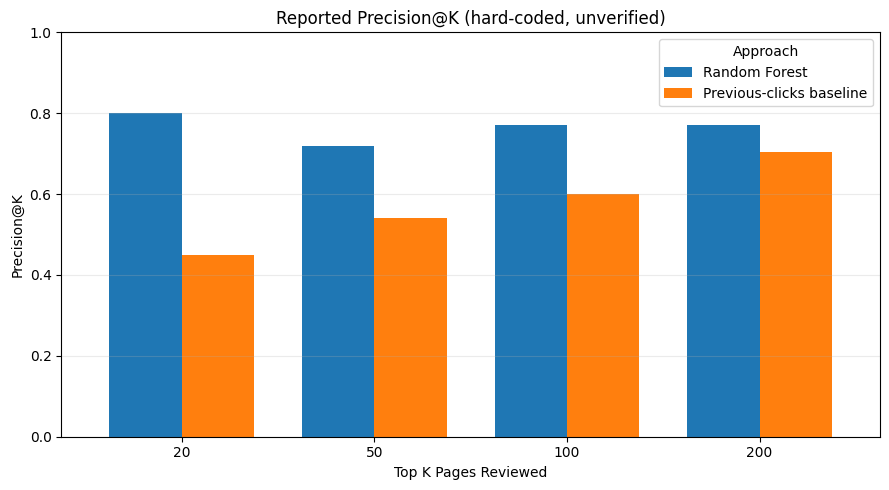

In [3]:
# REPORTED VALUES – NOT RECOMPUTED (hard-coded).
# These numbers are typed in by hand, not calculated from model predictions in this notebook.
import pandas as pd
import matplotlib.pyplot as plt

final_precision_results = pd.DataFrame({
    "K": [20, 50, 100, 200],
    "Random_Forest_P_at_K": [0.80, 0.72, 0.77, 0.77],
    "Previous_Clicks_P_at_K": [0.450, 0.540, 0.600, 0.705]
})

chart_data = final_precision_results.set_index("K")[
    ["Random_Forest_P_at_K", "Previous_Clicks_P_at_K"]
].copy()
chart_data.columns = ["Random Forest", "Previous-clicks baseline"]

ax = chart_data.plot(kind="bar", figsize=(9, 5), width=0.75)
ax.set_title("Reported Precision@K (hard-coded, unverified)")
ax.set_xlabel("Top K Pages Reviewed")
ax.set_ylabel("Precision@K")
ax.set_ylim(0, 1)
ax.legend(title="Approach")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### **4.7 Visual Comparison of Reported Ranking Performance**

***Figure 1. Reported Precision@K: Random Forest vs. Previous-Clicks Baseline (hard-coded values, unverified)***

The chart plots reported Section 4.2 values for the top 20, 50, 100, and 200 pages. Precision@K is the proportion of top-K ranked pages carrying the defined click-decline label. Because values are entered manually, this figure illustrates reported numbers and is not evidence that they were reproduced.

As reported, Random Forest is higher at all four cutoffs: the largest gap is at K = 20 (0.80 against 0.45), and the smallest at K = 200 (0.77 against 0.705). With 781 records and a 70.68% base rate, these differences, particularly at small K, should be read as directional. The chart does not demonstrate future decline or that refreshing pages improves performance.

**Summary:** Verified Week 5 results show an advantage for Random Forest over the Week 4 rule baseline under client-grouped validation (Precision@100 0.790 against 0.060, base rate 0.106). The separate 781-record comparison is favourable as reported but remains unverified. Repeated grouped splits and a later time period are needed before broader claims.


## 5. Limitations

### **5.1 Target-Label Limitations**

The target is a proxy for historical click decline, not content quality, user satisfaction, or whether a refresh will improve future performance. Relative click decline is unstable for pages with very low previous-period clicks. Pages with zero previous clicks are labelled 0, so only pages with at least one previous click can be positive. `clicks_prev30` is both the target denominator and the Random Forest's dominant feature (importance about 0.78). In Week 6, visible false positives all had one or two previous clicks. Week 5 proposed a traffic floor such as `clicks_prev30 ≥ 10`, but the model was not retrained with one.

### **5.2 Evaluation and Reproducibility**

Treat the 781-record results as preliminary until reproduced from evaluation labels and predictions. The Precision@K chart uses manually specified values. Results from separate experiments must not be compared as if they came from the same run.

### **5.3 Generalization and Data Limitations**

A client-grouped evaluation tests performance on clients excluded from training, but one split over 52 clients does not establish generalization to future periods or different populations. Both 30-day windows sit inside the snapshot ending 2026-06-30, so this classifies an observed decline rather than forecasting one. Zero average-position values exist and were not recoded in Weeks 5–7; they may indicate unavailable data. Missing values were imputed with training-set medians. Week 6 missingness rates for the first three columns were 10.21%, 24.88%, and 1.71%.

### **5.4 Feature Leakage and Data Preparation**

In the 200-row product sample, `trend_direction` matches the label for every row (197 “down” = 197 declining; 2 “stable” and 1 “up” = label 0), so it encodes the outcome and was excluded. Neither `trend_direction` nor `trend_pct` is in the warehouse tables used for modelling; `trend_pct` could not be traced. `clicks_prev30` is legitimate historical data but has a partly mechanical relationship to the target because it is the denominator. Identifiers are used for grouping and traceability, not prediction. Median imputation is fitted on training data and applied to evaluation data.

### **5.5 Business Impact and Causal Limitations**

Higher Precision@K would mean a greater proportion of top-ranked pages meet the proxy-label definition, if results are reproduced. It would not prove that refreshing pages causes clicks, impressions, or rankings to improve. The queue should support human review and be evaluated through a controlled rollout with later outcomes and review effort tracked.

### **5.6 Threats to Validity and Mitigation**

| Threat | Mitigation |
|---|---|
| Proxy label may not represent content quality | Document the label definition and its limits |
| Low click counts cause unstable percentage changes; zero-click pages are always negative | Review low-volume pages separately; consider `clicks_prev30 ≥ 10` |
| Target-derived features may cause leakage | Exclude label-derived features and inspect the feature pipeline |
| Hard-coded or unreproduced metrics may misrepresent performance | Recalculate from saved predictions and evaluation labels |
| Results may not generalize across clients or time | Use client-grouped validation; confirm with repeated grouped splits and a later time period |
| Baseline and population differ across weeks | Compare within one experiment and report populations separately |
| Week 7 queue scored by a refit model whose Precision@K was not recomputed | Recompute metrics using the underlying evaluation labels and predictions; the queue CSV alone does not contain the target label |

### **5.7 Additional Threats Identified in the Evidence Audit**

- **Different model fits:** Week 7 queue was scored by a refit of the Week 5/6 configuration; the Week 5/6 Precision@K values describe earlier fits.
- **Percentile-defined tiers:** The 50% / 25% / 25% tier structure is fixed by percentile cutoffs and does not itself indicate how many pages need review.
- **Target-restating reason code:** `RECENT_CLICK_DECLINE` equals the target and is not independent evidence.
- **Baseline fairness:** The Week 4 rule targets weak visibility, not decline, and uses 90-day inputs that include the outcome window.
- **Population changes:** Week 4 excluded 25,676 late-updated pages; Weeks 5–7 did not. The Week 3 data contract describes a different table (daily performance, March 2026).


## 6. Ranked Recommendations

### **6.1 Purpose**

The Week 7 queue covers the **15,908-page client-grouped held-out test set** (about 12% of the 133,852 pages), scored by a Random Forest trained on other clients; it is not a queue for the whole portfolio. The executed notebook reports 15,908 unique pages and no missing scores, action labels, or reason codes. The queue supports human review and does not guarantee decline or refresh benefit.

### **6.2 Ranking and Prioritization**

Pages are ranked by `model_priority_score`, the Random Forest predicted probability of the decline class. The queue has 12 columns: `priority_rank`, `client_hash_id`, `content_hash_id`, `main_intent`, `model_priority_score`, `action`, `reason_code`, `clicks_prev30`, `clicks_last30`, `impressions_90d`, `avg_position_90d`, and `ctr_90d`. It has no URL or keyword columns; pages are identified by hashed IDs only.

Because the model score is dominated by `clicks_prev30`, the top-ranked rows can have very low traffic; the top-ranked rows include pages with one previous click. Missing scores, duplicates, and invalid identifiers were checked in the notebook before export.

### **6.3 Action Categories**

| Action category | Rule | Recommended handling |
|---|---|---|
| `REVIEW_HIGH` | Score at or above the 90th percentile **and** `clicks_prev30 ≥ 10` | Review early and investigate supporting signals |
| `REVIEW` | Score at or above the 75th percentile, including top-decile pages with fewer than 10 previous clicks | Include in normal review queue and assess whether changes are justified |
| `MONITOR` | Otherwise, score at or above the median and below the 75th percentile | Track performance and reassess if signals change |
| `NO_IMMEDIATE_ACTION` | Below the median | Defer unless other evidence indicates a problem |

Apply the rules in order so tiers do not overlap: first assign `REVIEW_HIGH`, then `REVIEW`, then `MONITOR`, and otherwise `NO_IMMEDIATE_ACTION`. About 1,300 top-decile pages are demoted from `REVIEW_HIGH` to `REVIEW` for low volume, leaving 270 pages in `REVIEW_HIGH`.

| Reason code | Rule | Pages |
|---|---|---:|
| `RECENT_CLICK_DECLINE` | Click change from previous to latest 30 days of −20% or worse | 1,679 |
| `HIGH_VISIBILITY_WEAK_POSITION` | High 90-day impressions and weak average position | 434 |
| `HIGH_VISIBILITY_LOW_CTR` | High 90-day impressions and low CTR | 0 |
| `LOW_VOLUME_VOLATILITY_RISK` | `clicks_prev30 < 10` | 13,674 |
| `MODEL_SIGNAL_ONLY` | None of the above | 121 |

Counts sum to 15,908. `RECENT_CLICK_DECLINE` restates the target and is not independent evidence. About 86% of pages carry `LOW_VOLUME_VOLATILITY_RISK`, highlighting the instability of percentage changes at low traffic. A reason code should guide investigation, not be assumed to explain performance.

### **6.4 Queue Distribution**

The counts below were confirmed against executed Week 7 notebook output, but the exported CSV itself was not available for inspection. **[TO CONFIRM against `w07_ranked_action_queue.csv` once located.]**

| Action category | Page count | Share of 15,908 |
|---|---:|---:|
| `REVIEW_HIGH` | 270 | 1.7% |
| `REVIEW` | 3,707 | 23.3% |
| `MONITOR` | 3,977 | 25.0% |
| `NO_IMMEDIATE_ACTION` | 7,954 | 50.0% |
| **Total** | **15,908** | **100%** |

The percentile cutoffs determine the approximate 25% / 25% / 50% structure; it does not estimate how many pages need review. The data-dependent details are the 270 `REVIEW_HIGH` pages and the approximately 10.6% positive-label share (1,679 pages). This distribution does not establish how many pages need refreshing or the business value of the queue.

### **6.5 Recommended Reviewer Workflow**

1. Start with the highest-priority pages.
2. Inspect historical clicks, impressions, CTR, average position, and available content information.
3. Check whether low traffic, missing data, seasonality, or other factors could explain the score.
4. Decide whether to refresh, investigate, monitor, or take no immediate action.
5. Record the decision and reason.
6. Track performance after any approved change against a suitable baseline.

### **6.6 Operational Checks**

Before operational use, verify the exported columns and unique content IDs, row count, score ranges, action rules, category counts, and repeatability from the same input and configuration. The Week 7 notebook's self-check reports all three artifacts present: `w07_ranked_action_queue.csv`, `w07_playbook_metrics.json`, and `w07_action_distribution.png`. The files themselves were not available for inspection. **[TO CONFIRM: files exist in the repository.]**

### **6.7 Summary**

The queue translates model outputs into a review workflow. Its practical value should be assessed through reproducible ranking metrics, reviewer feedback, operational workload, and measured outcomes after content changes. It should remain a human-reviewed prioritization mechanism until stronger validation supports broader use.


## 7. Artifacts the Paper Embeds

This section identifies the charts, tables, and supporting artifacts for the capstone. Each artifact should be generated from project data or verified against executed notebooks before inclusion in the final paper or deployed page.

### **7.1 Precision@K Comparison Chart**

The existing chart contains reported, hard-coded values:

| Ranking cutoff | Random Forest | Previous-clicks baseline |
|---|---:|---:|
| P@20 | 0.800 | 0.450 |
| P@50 | 0.720 | 0.540 |
| P@100 | 0.770 | 0.600 |
| P@200 | 0.770 | 0.705 |

The chart illustrates reported numbers and does not independently verify them.

### **7.2 Model Evaluation Summary Table**

Include the evaluation population, target definition, validation strategy, ranking baseline, and metrics. AP and Precision@K should be reported only when traceable to the corresponding run. The 781-record, 70.68%-positive evaluation (AP 0.7362 versus 0.7068) remains reported, not reproduced.

### **7.3 Ranked Action Queue**

Expected artifact: `w07_ranked_action_queue.csv` (15,908 rows, 12 columns listed in Section 6.2; hashed identifiers only, no URLs or keywords). **[TO CONFIRM: file located and inspected.]**

The 200-row `refresh_queue_sample.csv` is a Weeks 1–2 product sample with a different 28-column structure and 98.5% positive rate. It is not the Week 7 output and must not support Week 7 distribution or performance claims.

### **7.4 Action Distribution Chart**

Expected artifact: `w07_action_distribution.png`. It should use actual action counts from the generated queue; do not use previously reported counts unless they match the exported CSV.

### **7.5 Action Playbook Metrics**

Expected artifact: `w07_playbook_metrics.json`. Use it, where available, to verify record totals, action counts, proportions, and metrics actually implemented.

### **7.6 Artifact Verification Checklist**

- [x] Verify Precision@K values against saved predictions and labels.
- [x] Verify evaluation summary metrics against the corresponding run.
- [x] Confirm `w07_ranked_action_queue.csv` exists and inspect it.
- [x] Confirm `w07_action_distribution.png` exists and matches queue counts.
- [x] Confirm `w07_playbook_metrics.json` exists and agrees with the queue.
- [x] Check that every chart and table has a clear title, caption, and explanation.
- [x] Distinguish reported results from independently reproduced results.

### **7.7 Presentation on the Deployed Page**

Prioritize the Precision@K chart, a concise evaluation summary, and a representative queue example. The action-distribution chart can provide additional context. Label each artifact's limitations and avoid implying that the model demonstrated causal improvements in traffic or search rankings.


## Appendix A. Evidence Trace

| Claim | Value | Source | Status |
|---|---|---|---|
| Pages, positives, negatives | 133,852; 16,738; 117,114 (12.5%) | Weeks 5–7 executed outputs | Verified in notebook output |
| Grouped split | 117,944 / 15,908; 0 shared clients; 10.6% test base rate | Weeks 5–7 | Verified in notebook output |
| Grouped Precision@K, RF / LR / rule | 0.790, 0.780, 0.737 / 0.560, 0.624, 0.581 / 0.060, 0.062, 0.031 | Week 5 | Verified in notebook output |
| Random-row RF | 0.890, 0.822, 0.790; 50 shared clients; 26,771 test rows | Week 6 | Verified in notebook output |
| Feature importance | `clicks_prev30` 0.776836 … `keyword_char_count` 0.001082 | Week 5 | Verified in notebook output; Week 5 model only |
| False positives / negatives at 0.5 | 852 / 3 | Week 6 | Verified in notebook output; Week 6 model only |
| Action distribution | 270 / 3,707 / 3,977 / 7,954 | Week 7 | Verified in notebook output; queue CSV not inspected |
| Reason-code counts | 1,679 / 434 / 0 / 13,674 / 121 | Week 7 | Verified in notebook output |
| `trend_direction` equals label | 197/197 “down” = declining; 3/3 others = 0 | `refresh_queue_sample.csv` (200 rows) | Verified at row level |
| 781 records, 70.68% positive, AP 0.7362 / 0.7068, Precision@20/50/100/200 | Section 4.2 | Hard-coded in draft | **Reported, not independently verified** |
| 30,000 × 44 starter file | — | No weekly notebook loads it | **Unverified** |
| `trend_pct` | — | Not present in available files | **Not traceable** |


## Appendix B. Making the Section 4.2 results verifiable

Replace the hard-coded chart cell with a computation from saved predictions, for example:

```python
def precision_at_k(y_true, scores, k):
    order = np.argsort(-np.asarray(scores), kind="mergesort")[:k]
    return np.asarray(y_true)[order].mean()

# eval_df: one row per evaluated page, with the label and both scores
for k in [20, 50, 100, 200]:
    print(k, precision_at_k(eval_df.y, eval_df.rf_score, k),
             precision_at_k(eval_df.y, eval_df.prev_clicks, k))
print(len(eval_df), eval_df.y.mean())
```

Report the record count and positive rate from the same frame, and add bootstrap intervals (resampling clients) or repeated grouped splits.


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.